
# EXERCISES E: Evaluations of Classification ML Techniques

N.B. The exercise 3 comes from examples given in <i>Hands-On Machine Learning 3rd Ed., A. Géron, O'Reilly, 2023, Chapter 3</i>, 
that were discussed during the course.

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Analysis of Binary Classifiers on Artificial 1D Datasets

In this exercise, we aim at better understanding the notions of recall and precision based on simple classification problems.

### 1.1 Build the datasets
(similar as in the preceding set of exercises)

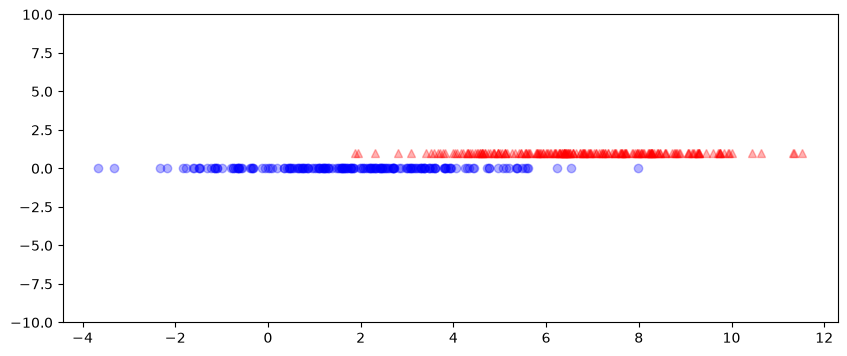

In [24]:
def gaussian_1D_generation(mean, standard_deviation,  N):
    X = (standard_deviation * np.random.randn(N) + mean).reshape(-1,1)
    return X

size_class_0 = 300
size_class_1 = 300

X_0 = gaussian_1D_generation(2, 2, size_class_0) 
X_1 = gaussian_1D_generation(7, 2, size_class_1)

Y_0 = np.zeros(size_class_0, dtype=int)
Y_1 = np.ones(size_class_1, dtype=int)

X = np.concatenate((X_0, X_1))
Y = np.concatenate((Y_0, Y_1))

X_train, X_valid, y_train, y_valid = train_test_split(X, Y, test_size=0.33, random_state=42)

plt.figure(figsize=(10, 4))
plt.ylim([-10,10])
plt.plot(X_train[y_train == 0], y_train[y_train == 0], "bo", alpha=0.3)
plt.plot(X_train[y_train == 1], y_train[y_train == 1], "r^", alpha=0.3)
plt.show()

# N.B: Here, by keeping the labels to 1 for the "r^ class" (class 1), and extending the y interval to -10,10, 
#      the representation of the two classes do not overlap. 

### 1.2 Classify with step functions  

Consider the generalizations/models in the plain form of a binary step function to decide the class ($0$ or $1$) for any point belonging to the line $\mathbb{R}$ : $$h_\theta(x) = \begin{cases}1 & \mathrm{if}\:sign \cdot x \geq bound\\0 & \mathrm{otherwise}\end{cases}$$
where $\theta=(sign,bound)$ with:
- $sign$ can be $-1$ or $1$, 
- $bound \in \mathbb{R}$ (the boundary decision).

Implement this simple parameterized step function and then:
- Test it for various values of $sign$ and $bound$ (with regard to the above dataset),
- Display the corresponding confusion matrix for each of them (hint: use the function `confusion_matrix` of `sklearn.metrics`).<br>
  The matrices are $\begin{pmatrix}\#TN & \#FP \\ \#FN & \#TP \end{pmatrix}$ like in the course slides.
- Understand the results.

## correction
## On implémente la fonction en escalier 

In [25]:
from sklearn.metrics import confusion_matrix

def step_function(X, sign, bound):
    return (sign * X >= bound).astype(int)
    

### on teste  différentes valeurs de sign et bound

In [26]:
parameters = [(1, 3), (1, 4), (1, 5),(1, 6), (1, 7), 
    (-1, -3), (-1, -4),(-1, -5),(-1, -6),(-1, -7)]

## On applique ensuite chaque modèle aux données de validation :

for sign, bound in parameters:
    y_pred = step_function(X_valid, sign, bound )
    print("sign =", sign, "bound =", bound)
    print("Predictions :", y_pred[:20])
    print()

sign = 1 bound = 3
Predictions : [[0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = 1 bound = 4
Predictions : [[0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = 1 bound = 5
Predictions : [[0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = 1 bound = 6
Predictions : [[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = 1 bound = 7
Predictions : [[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]]

sign = -1 bound = -3
Predictions : [[1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]]

sign = -1 bound = -4
Predictions : [[1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]]

sign = -1 bound = -5
Predictions : [[1]
 [1]
 [0]
 

### Affichage de la matrice de confusion pour chaque modèle

In [27]:
for sign, bound in parameters:
    y_pred = step_function(X_valid, sign, bound)
    cm = confusion_matrix(y_valid, y_pred)

    print("--------------------------------")
    print("sign =", sign, "bound =", bound)
    print()
    print(cm)
    print()

--------------------------------
sign = 1 bound = 3

[[77 27]
 [ 6 88]]

--------------------------------
sign = 1 bound = 4

[[90 14]
 [ 7 87]]

--------------------------------
sign = 1 bound = 5

[[101   3]
 [ 17  77]]

--------------------------------
sign = 1 bound = 6

[[103   1]
 [ 34  60]]

--------------------------------
sign = 1 bound = 7

[[104   0]
 [ 43  51]]

--------------------------------
sign = -1 bound = -3

[[27 77]
 [88  6]]

--------------------------------
sign = -1 bound = -4

[[14 90]
 [87  7]]

--------------------------------
sign = -1 bound = -5

[[  3 101]
 [ 77  17]]

--------------------------------
sign = -1 bound = -6

[[  1 103]
 [ 60  34]]

--------------------------------
sign = -1 bound = -7

[[  0 104]
 [ 51  43]]



### affichage de  TN, FP, FN et TP

In [28]:
for sign, bound in parameters:
    y_pred = step_function( X_valid, sign, bound )

    cm = confusion_matrix(y_valid, y_pred)
    TN = cm[0, 0]
    FP = cm[0, 1]
    FN = cm[1, 0]
    TP = cm[1, 1]

    print("--------------------------------")
    print("sign =", sign, "bound =", bound)

    print("TN =", TN)
    print("FP =", FP)
    print("FN =", FN)
    print("TP =", TP)
    print()

--------------------------------
sign = 1 bound = 3
TN = 77
FP = 27
FN = 6
TP = 88

--------------------------------
sign = 1 bound = 4
TN = 90
FP = 14
FN = 7
TP = 87

--------------------------------
sign = 1 bound = 5
TN = 101
FP = 3
FN = 17
TP = 77

--------------------------------
sign = 1 bound = 6
TN = 103
FP = 1
FN = 34
TP = 60

--------------------------------
sign = 1 bound = 7
TN = 104
FP = 0
FN = 43
TP = 51

--------------------------------
sign = -1 bound = -3
TN = 27
FP = 77
FN = 88
TP = 6

--------------------------------
sign = -1 bound = -4
TN = 14
FP = 90
FN = 87
TP = 7

--------------------------------
sign = -1 bound = -5
TN = 3
FP = 101
FN = 77
TP = 17

--------------------------------
sign = -1 bound = -6
TN = 1
FP = 103
FN = 60
TP = 34

--------------------------------
sign = -1 bound = -7
TN = 0
FP = 104
FN = 51
TP = 43



### Intrepretation de resultat

### Choisir le meilleur sign

### 1.3 Plot the precision and recall curves

Use the value that seems the best for $sign$, and plot the recall and precision curves against $bound$
with $1$ as the predominant class (here, it is possible to use the functions `recall_score` and `precision_score` of `sklearn`).

### Faire varier bound

In [29]:
from sklearn.metrics import precision_score, recall_score

# On crée une liste de valeurs 
bounds = np.linspace(-5, 15, 300)

# puis on calcule precision et recall.
precisions = []
recalls = []
sign = 1

for bound in bounds:
    y_pred = step_function( X_valid, sign,bound)
    precision = precision_score( y_valid, y_pred, zero_division=0 )
    recall = recall_score( y_valid, y_pred, zero_division=0)
    precisions.append(precision)
    recalls.append(recall)

### tracer les courbes

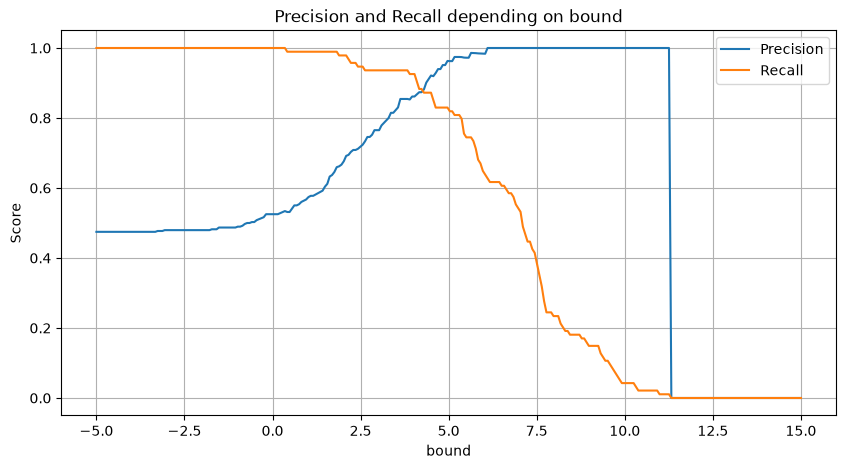

In [30]:
plt.figure(figsize=(10, 5))
plt.plot(bounds, precisions, label="Precision")
plt.plot(bounds, recalls, label="Recall")

plt.xlabel("bound")
plt.ylabel("Score")
plt.title("Precision and Recall depending on bound")

plt.legend()
plt.grid()
plt.show()

### Interpretation

### 1.4 Plot the ROC curves
Do the same as above but for the ROC curve, and print the AUC
(hint: use the functions `rec_curve` and `auc` of `sklearn`).

### Calculer TPR et FPR

In [31]:
bounds = np.linspace(-5, 15, 300)
TPR = []
FPR = []
sign = 1

for bound in bounds:
    y_pred = step_function(X_valid, sign, bound)
    cm = confusion_matrix(y_valid, y_pred)

    TN = cm[0, 0]
    FP = cm[0, 1]
    FN = cm[1, 0]
    TP = cm[1, 1]

    tpr = TP / (TP + FN) if (TP + FN) != 0 else 0
    fpr = FP / (FP + TN) if (FP + TN) != 0 else 0

    TPR.append(tpr)
    FPR.append(fpr)

### Calculer l'AUC

In [32]:
from sklearn.metrics import auc

roc_auc = auc(FPR, TPR)
print("AUC =", roc_auc)

AUC = 0.9578559738134207


### Tracer la ROC

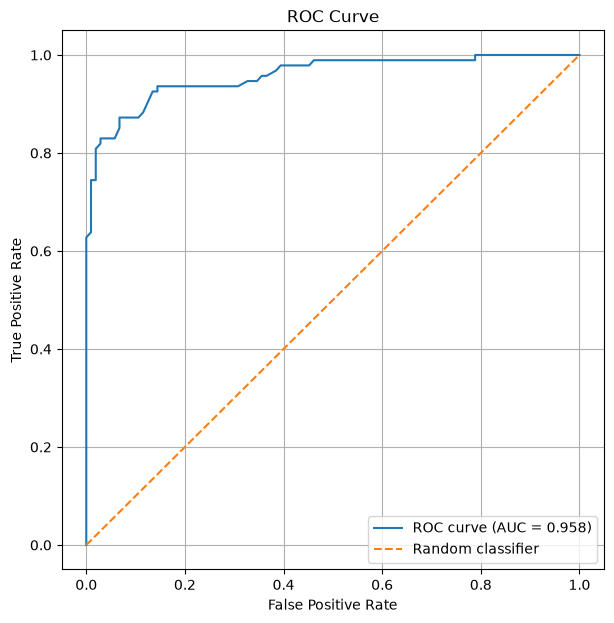

In [33]:
plt.figure(figsize=(7, 7))
plt.plot(FPR, TPR, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid()
plt.show()

### 1.5 Do the same as above with different datasets
Use different sizes of datasets, different balances between the two classes, different Gaussians, and different configurations of overlaps between classes. Implement other generation functions to get more configurations. Try to obtain different graph forms for the curves, and be sure you understand them.
 

In [34]:
def plot_precision_recall(X_valid, y_valid, sign=1):
    bounds = np.linspace(np.min(X_valid) - 1, np.max(X_valid) + 1, 300)
    precisions = []
    recalls = []

    for bound in bounds:
        y_pred = step_function(X_valid, sign, bound)

        precisions.append(
            precision_score(y_valid, y_pred, zero_division=0 )
        )
        recalls.append(
            recall_score( y_valid, y_pred, zero_division=0 )
        )

    plt.figure(figsize=(10, 5))
    plt.plot(bounds, precisions, label="Precision")
    plt.plot(bounds, recalls, label="Recall")

    plt.xlabel("bound")
    plt.ylabel("Score")
    plt.title("Precision and Recall depending on bound")
    plt.legend()
    plt.grid()
    plt.show()

In [35]:
def plot_roc(X_valid, y_valid, sign=1):
    bounds = np.linspace(np.min(X_valid) - 1, np.max(X_valid) + 1, 300)

    TPR = []
    FPR = []
    for bound in bounds:
        y_pred = step_function(X_valid, sign, bound)

        cm = confusion_matrix(y_valid, y_pred)
        TN = cm[0, 0]
        FP = cm[0, 1]
        FN = cm[1, 0]
        TP = cm[1, 1]

        tpr = TP / (TP + FN) if TP + FN > 0 else 0
        fpr = FP / (FP + TN) if FP + TN > 0 else 0
        TPR.append(tpr)
        FPR.append(fpr)

    roc_auc = auc(FPR, TPR)
    plt.figure(figsize=(7, 7))
    plt.plot(FPR, TPR, label=f"ROC (AUC = {roc_auc:.3f})")

    plt.plot([0, 1], [0, 1], "--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid()
    plt.show()
    print("AUC =", roc_auc)

### Dataset initial fourni dans l'énoncé

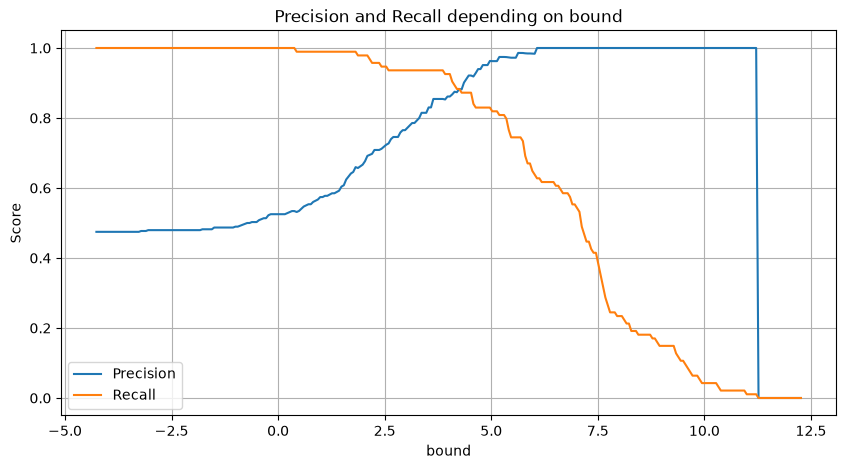

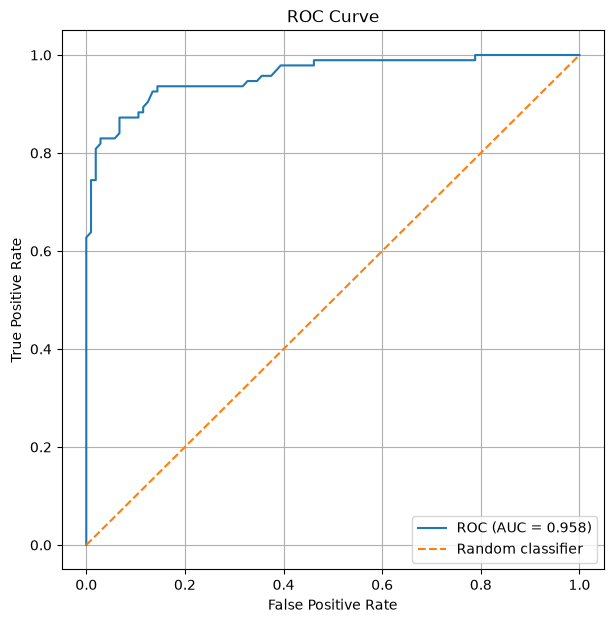

AUC = 0.957753682487725


In [36]:
X_train, X_valid, y_train, y_valid = train_test_split(X, Y, test_size=0.33, random_state=42)
plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)

### classes très séparées

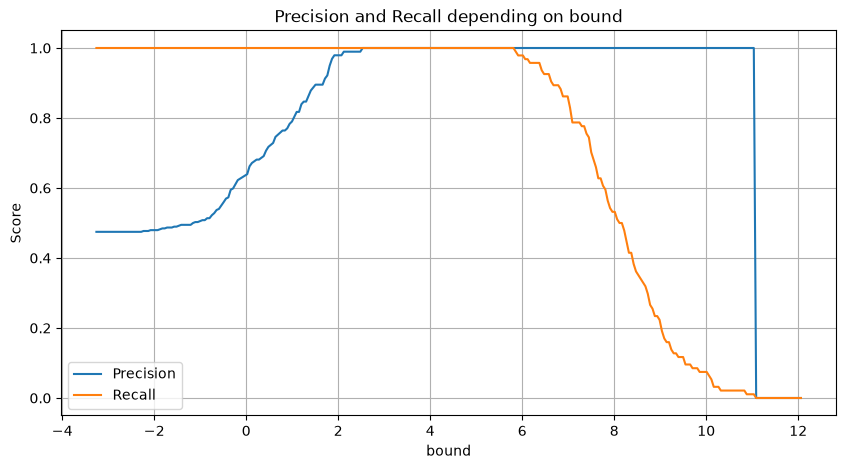

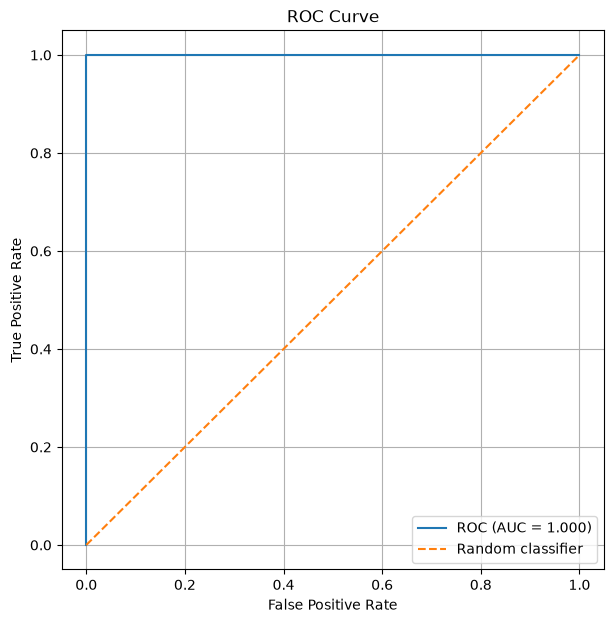

AUC = 1.0


In [37]:
def generate_dataset_1():
    size_class_0 = 300
    size_class_1 = 300

    X_0 = gaussian_1D_generation(0, 1, size_class_0)
    X_1 = gaussian_1D_generation(8, 1, size_class_1 )
    Y_0 = np.zeros(size_class_0, dtype=int)
    Y_1 = np.ones(size_class_1, dtype=int )
    X = np.concatenate((X_0, X_1))
    Y = np.concatenate((Y_0, Y_1))
    return train_test_split(X, Y, test_size=0.33, random_state=42)

X_train, X_valid, y_train, y_valid = generate_dataset_1()
plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)

### Classes qui se chevauchent fortement

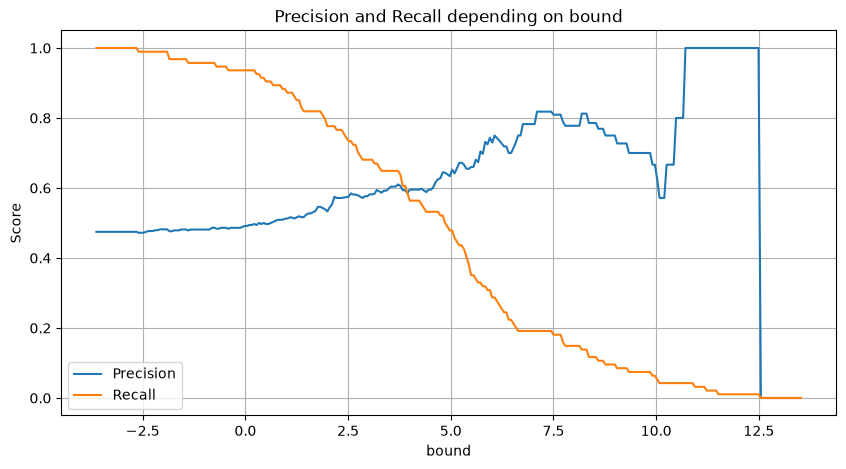

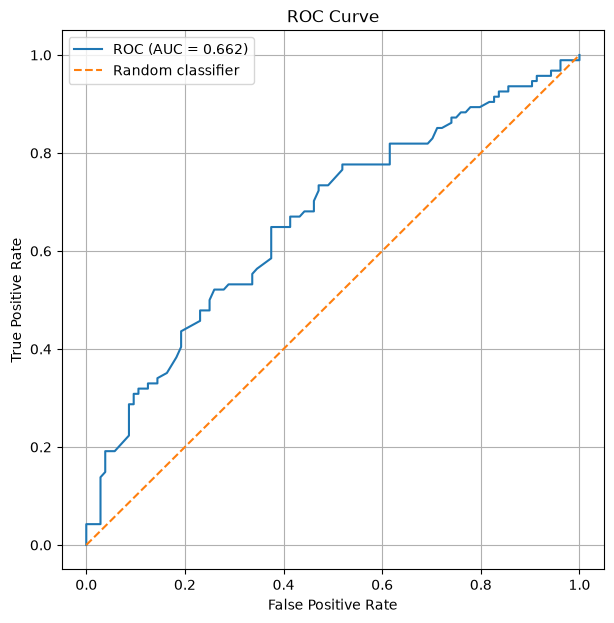

AUC = 0.6622851882160392


In [38]:
def generate_dataset_2():
    size_class_0 = 300
    size_class_1 = 300

    X_0 = gaussian_1D_generation(3, 3, size_class_0)
    X_1 = gaussian_1D_generation(5, 3, size_class_1 )
    Y_0 = np.zeros(size_class_0, dtype=int )
    Y_1 = np.ones(size_class_1, dtype=int)
    X = np.concatenate((X_0, X_1))
    Y = np.concatenate((Y_0, Y_1))
    return train_test_split(X, Y, test_size=0.33, random_state=42)
X_train, X_valid, y_train, y_valid = generate_dataset_2()

plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)


### Classes déséquilibrées

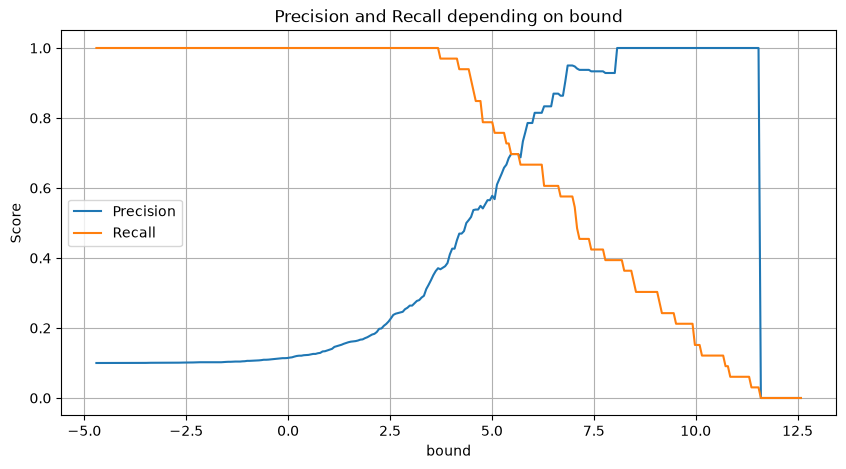

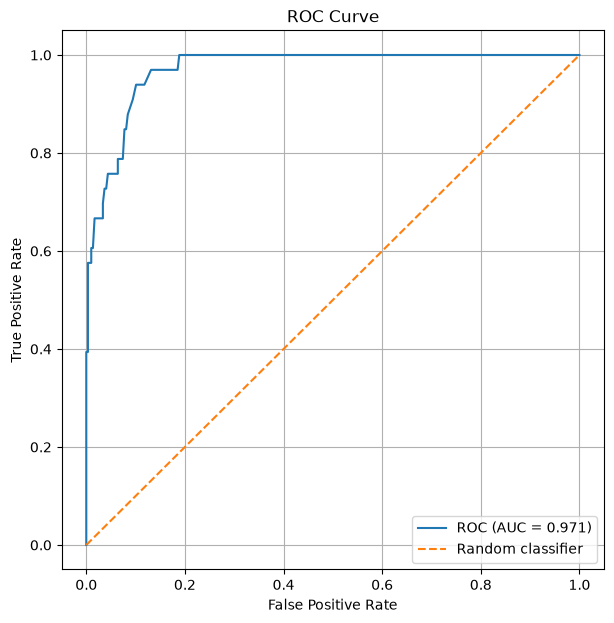

AUC = 0.9706662585450464


In [39]:
def generate_dataset_3():
    size_class_0 = 900
    size_class_1 = 100

    X_0 = gaussian_1D_generation(2, 2, size_class_0)
    X_1 = gaussian_1D_generation(7, 2, size_class_1)
    Y_0 = np.zeros(size_class_0, dtype=int)
    Y_1 = np.ones( size_class_1, dtype=int )
    X = np.concatenate((X_0, X_1))
    Y = np.concatenate((Y_0, Y_1))

    return train_test_split(X, Y, test_size=0.33, random_state=42, stratify=Y)

X_train, X_valid, y_train, y_valid = generate_dataset_3()
plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)

Classes presque parfaitement séparées

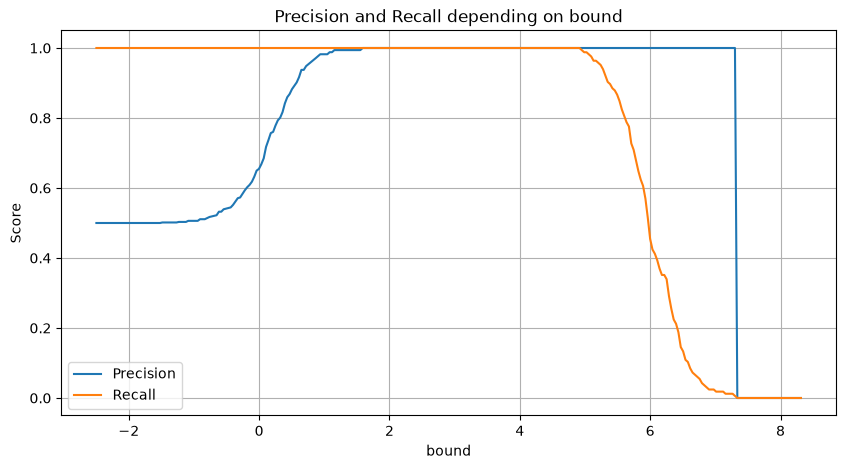

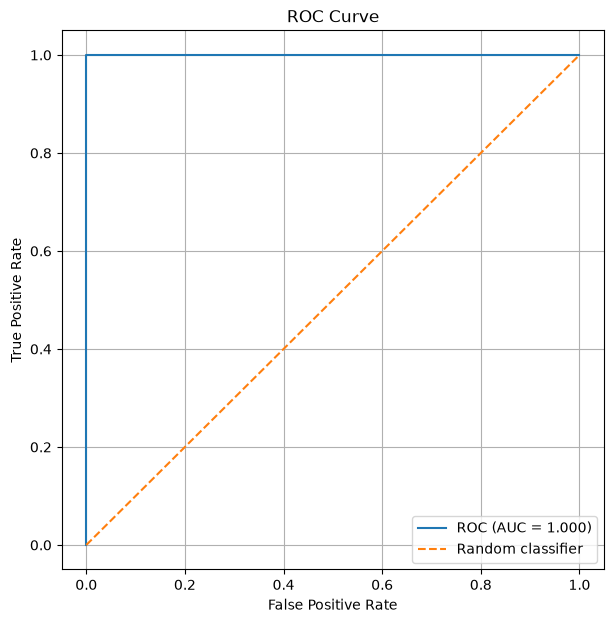

AUC = 1.0


In [40]:
def generate_dataset_4():
    size_class_0 = 500
    size_class_1 = 500

    X_0 = gaussian_1D_generation(0, 0.5, size_class_0)
    X_1 = gaussian_1D_generation( 6, 0.5, size_class_1)
    Y_0 = np.zeros(size_class_0, dtype=int)
    Y_1 = np.ones(size_class_1, dtype=int)
    X = np.concatenate((X_0, X_1))
    Y = np.concatenate((Y_0, Y_1))
    return train_test_split(X, Y, test_size=0.33, random_state=42)

X_train, X_valid, y_train, y_valid = generate_dataset_4()
plot_precision_recall(X_valid, y_valid, sign=1)
plot_roc(X_valid, y_valid, sign=1)

## 2. Classification of images of handwritten digits (MNIST)

The purpose of this classic exercise is to train classifiers to distinguish handwritten digits based on the MNIST dataset, i.e. images 28x28 of the 10 possible digits.

### 2.1 Load and explore the dataset

Use the code below to download MNIST and store it into the variable mnist.

In [41]:
from sklearn.datasets import fetch_openml
from matplotlib import pyplot as plt
mnist = fetch_openml('mnist_784', as_frame=False) #Numpy arrays instead of Pandas DataFrames

In [42]:
print(mnist.keys())

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])


In [43]:
mnist['data']

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784))

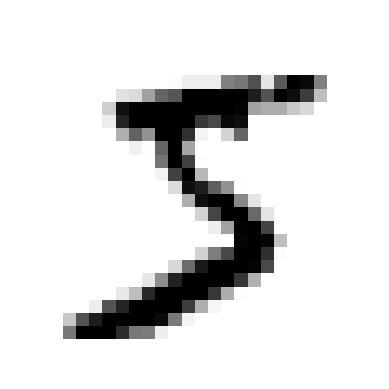

In [44]:
def plot_digit(image_data): 
    image = image_data.reshape(28, 28) 
    plt.imshow(image, cmap="binary") 
    plt.axis("off")

some_digit = mnist['data'][0] 
plot_digit(some_digit) 
plt.show()

#### Séparer les images (`X`) et les chiffres (`y`)

On veut récupérer dans `X` les pixels et dans `y` le chiffre de chaque image à partir de `mnist`, et compter les images par chiffre. Attention : `y` contient des **textes** ('0', '1', ...), pas des nombres.

In [45]:
X = mnist['data']      # une ligne = une image (784 pixels entre 0 et 255)
y = mnist['target']    # le chiffre de chaque image (en texte)
print("images :", X.shape, "| étiquettes :", y.shape)
print("nombre d'images par chiffre :", np.unique(y, return_counts=True)[1])

images : (70000, 784) | étiquettes : (70000,)
nombre d'images par chiffre : [6903 7877 6990 7141 6824 6313 6876 7293 6825 6958]


**Commentaire :** On a 70 000 images de 784 pixels (28 x 28). Les 10 chiffres sont à peu près **équilibrés** : de 6 313 images pour le 5 à 7 877 pour le 1, soit environ 9 % à 11 % chacun. Il n'y a donc pas de chiffre rare qui fausserait l'accuracy (on le retrouvera plus bas : `class_weight='balanced'` n'apporte rien).

#### Un exemple de chaque chiffre

On veut afficher un exemple de chaque chiffre, et en particulier le « 5 » (celui du cours, celui qui sert d'exemple pour « 5 contre pas 5 »).

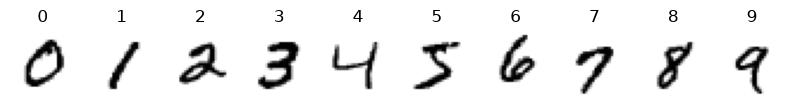

In [46]:
plt.figure(figsize=(10, 2))
for chiffre in range(10):
    plt.subplot(1, 10, chiffre + 1)
    premiere_image = X[y == str(chiffre)][0]     # première image de ce chiffre
    plot_digit(premiere_image)
    plt.title(chiffre)
plt.show()

**Commentaire :** Un exemple de chaque chiffre. On voit que l'écriture est très variable (épaisseur, inclinaison) : le « 5 » ressemble par endroits à un « 3 » ou à un « 6 », le « 4 » à un « 9 ». C'est de là que viendront les erreurs.

### 2.2 Train classifiers with reduced datasets

1. Apply a partition of the dataset to create a training and a test set (80%/20%).
2. Since a full training on all the images of the training dataset can be pretty long, start by extracting only a fraction of it, like $\frac{1}{64}$. This smaller dataset will make the experiments much quicker. Check the size of the obtained training dataset.
3. Train a classifier using, e.g.,`SGDClassifier`.

On veut séparer les données en 80 % pour l'entraînement et 20 % pour le test, puis garder seulement 1/64 de l'entraînement pour que les essais soient rapides. Le jeu de test, lui, reste entier.

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("entraînement complet :", len(X_train), "| test :", len(X_test))

petit = len(X_train) // 64                 # 1/64 du jeu d'entraînement
X_petit, y_petit = X_train[:petit], y_train[:petit]
print("entraînement réduit (1/64) :", len(X_petit))

entraînement complet : 56000 | test : 14000
entraînement réduit (1/64) : 875


**Commentaire :** Avec 80 % / 20 % on obtient 56 000 images d'entraînement et 14 000 de test. En gardant 1/64 de l'entraînement, il reste **875 images**, soit environ 87 par chiffre pour apprendre 784 pixels. Le jeu de test est grand : une différence de 1 point d'accuracy représente 140 images, donc les comparaisons sont assez fiables.

#### Premier modèle (paramètres par défaut)

On veut entraîner un premier classifieur `SGDClassifier` (descente de gradient) sur le petit jeu, avec les paramètres par défaut, et mesurer son accuracy sur l'entraînement et sur le test.

In [48]:
from sklearn.linear_model import SGDClassifier

modele = SGDClassifier(random_state=42)
modele.fit(X_petit, y_petit)
print("accuracy entraînement :", round(modele.score(X_petit, y_petit), 3))
print("accuracy test         :", round(modele.score(X_test, y_test), 3))

accuracy entraînement : 1.0
accuracy test         : 0.845


c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


**Commentaire :** Le modèle par défaut a **100 % sur l'entraînement mais 84,5 % sur le test** : c'est du **surapprentissage**. Avec seulement 875 images et 784 pixels (beaucoup de paramètres), il apprend presque par cœur les images vues et généralise moins bien. L'avertissement `ConvergenceWarning` veut dire que la descente de gradient a atteint son nombre maximal d'itérations avant de converger complètement ; il n'est pas grave ici.

### 2.3 Obtain and plot the confusion matrices
1. Use `confusion_matrix` of `sklearn.metrics` as well as `matshow` of `matplot` to visualize the matrices.
2. Study the high values of errors in the matrices and the cases that produce them.

On veut calculer la matrice de confusion du modèle sur le test (ligne = vrai chiffre, colonne = chiffre prédit) et la dessiner avec `matshow`. La diagonale contient les bonnes réponses, tout le reste ce sont des erreurs.

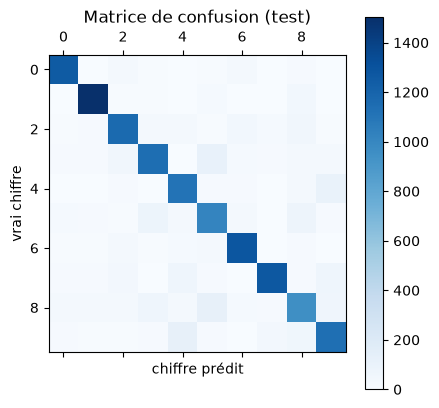

In [49]:
from sklearn.metrics import confusion_matrix

y_pred = modele.predict(X_test)
matrice = confusion_matrix(y_test, y_pred)

plt.matshow(matrice, cmap="Blues")
plt.title("Matrice de confusion (test)")
plt.xlabel("chiffre prédit"); plt.ylabel("vrai chiffre")
plt.colorbar()
plt.show()

**Commentaire :** La diagonale (les bonnes réponses) est très foncée : le modèle a raison dans la grande majorité des cas. Le « 1 » est le mieux reconnu (le plus foncé, il y a aussi plus d'images de 1) ; les cases de la diagonale des chiffres **5 et 8** sont un peu plus claires, ces chiffres sont donc plus souvent ratés. Les erreurs sont trop pâles pour être étudiées sur cette figure, d'où la figure suivante.

#### Erreurs seulement (sans la diagonale)

On veut voir les erreurs, mais la diagonale (les bonnes réponses) écrase tout le reste. On la met donc à zéro et on divise chaque ligne par le nombre d'images de ce chiffre : on voit alors **la part des images de chaque chiffre qui est confondue avec chaque autre chiffre**. On affiche aussi les 5 confusions les plus fréquentes.

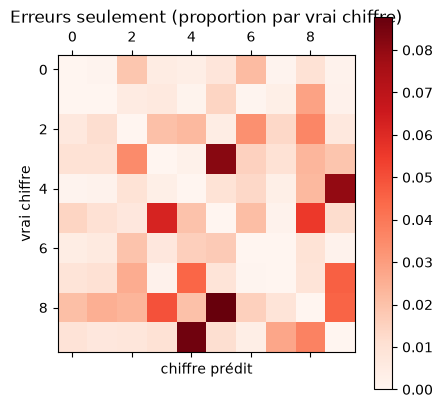

vrai 9 prédit 4 : 122 images
vrai 8 prédit 5 : 119 images
vrai 3 prédit 5 : 117 images
vrai 4 prédit 9 : 103 images
vrai 5 prédit 3 : 79 images


In [50]:
sans_diagonale = matrice / matrice.sum(axis=1, keepdims=True)   # proportions par ligne
np.fill_diagonal(sans_diagonale, 0)                             # on enlève les bonnes réponses

plt.matshow(sans_diagonale, cmap="Reds")
plt.title("Erreurs seulement (proportion par vrai chiffre)")
plt.xlabel("chiffre prédit"); plt.ylabel("vrai chiffre")
plt.colorbar()
plt.show()

# les 5 confusions les plus fréquentes (en nombre d'images)
erreurs = matrice.copy()
np.fill_diagonal(erreurs, 0)
for k in np.argsort(erreurs, axis=None)[::-1][:5]:
    vrai, predit = divmod(k, 10)
    print(f"vrai {vrai} prédit {predit} : {erreurs[vrai, predit]} images")

**Commentaire :** Sans la diagonale, les erreurs apparaissent. Les confusions les plus fréquentes (en nombre d'images, sur 14 000 images de test) sont :

| vrai chiffre | prédit | images |
|---|---|---|
| 9 | 4 | 122 |
| 8 | 5 | 119 |
| 3 | 5 | 117 |
| 4 | 9 | 103 |
| 5 | 3 | 79 |

Ce sont des **chiffres qui se ressemblent** : 4 et 9 (confusion dans les deux sens), 3, 5 et 8 (traits arrondis et ouverts du même côté). Un modèle linéaire qui regarde les pixels un par un ne voit pas bien les petites différences de forme (une boucle fermée ou ouverte). Les chiffres 0, 1 et 6 sont rarement mal classés.

#### Exemples d'images mal classées

On veut regarder à l'œil quelques images mal classées pour comprendre d'où viennent les erreurs (chiffre mal écrit, forme proche d'un autre chiffre...). Ici on prend les erreurs du couple le plus fréquent.

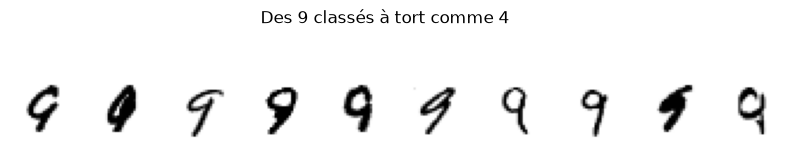

In [51]:
vrai, predit = divmod(np.argmax(erreurs), 10)       # couple le plus confondu
mal_classees = X_test[(y_test == str(vrai)) & (y_pred == str(predit))]

plt.figure(figsize=(10, 2))
for i in range(min(10, len(mal_classees))):
    plt.subplot(1, 10, i + 1)
    plot_digit(mal_classees[i])
plt.suptitle(f"Des {vrai} classés à tort comme {predit}")
plt.show()

**Commentaire :** Parmi les « 9 » pris pour des « 4 », beaucoup sont **écrits avec la boucle du haut peu fermée ou très penchée**, donc ils ressemblent vraiment à un 4. Certains seraient difficiles à lire même pour une personne : ce sont des **erreurs intrinsèques**, qu'aucun modèle ne pourra totalement supprimer. D'autres sont corrects à l'œil, l'erreur vient alors du modèle, trop simple et entraîné sur peu de données.

### 2.4 Do the same as above with different hyperparameters
Use different hyperparameters to improve the obtained confusion matrices.

On veut comparer plusieurs réglages du `SGDClassifier` sur le même petit jeu : avec ou sans normalisation des pixels (division par 255), et avec différentes valeurs de `alpha` (régularisation : plus `alpha` est grand, plus les poids sont contraints). On regarde l'accuracy d'entraînement et de test pour repérer le surapprentissage.

In [52]:
X_petit_n, X_test_n = X_petit / 255, X_test / 255     # pixels entre 0 et 1

essais = {
    "défaut (pixels bruts)": (SGDClassifier(random_state=42), X_petit, X_test),
    "pixels / 255": (SGDClassifier(random_state=42), X_petit_n, X_test_n),
    "pixels / 255, alpha=0.001": (SGDClassifier(alpha=0.001, random_state=42), X_petit_n, X_test_n),
    "pixels / 255, alpha=0.01": (SGDClassifier(alpha=0.01, random_state=42), X_petit_n, X_test_n),
    "pixels / 255, alpha=0.1": (SGDClassifier(alpha=0.1, random_state=42), X_petit_n, X_test_n),
    "pixels / 255, perte log_loss": (SGDClassifier(loss="log_loss", random_state=42), X_petit_n, X_test_n),
    "pixels / 255, class_weight=balanced": (SGDClassifier(class_weight="balanced", random_state=42), X_petit_n, X_test_n),
}
modeles = {}
for nom, (m, Xa, Xt) in essais.items():
    m.fit(Xa, y_petit)
    modeles[nom] = m
    print(f"{nom:38s} | train={m.score(Xa, y_petit):.3f} | test={m.score(Xt, y_test):.3f}")

c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


défaut (pixels bruts)                  | train=1.000 | test=0.845
pixels / 255                           | train=0.994 | test=0.822
pixels / 255, alpha=0.001              | train=0.995 | test=0.829
pixels / 255, alpha=0.01               | train=0.982 | test=0.857
pixels / 255, alpha=0.1                | train=0.928 | test=0.850
pixels / 255, perte log_loss           | train=1.000 | test=0.826
pixels / 255, class_weight=balanced    | train=1.000 | test=0.833


**Commentaire :** Résultats sur 875 images d'entraînement :

| réglage | train | test |
|---|---|---|
| défaut (pixels bruts) | 1.000 | 0.845 |
| pixels / 255 | 0.994 | 0.822 |
| pixels / 255, alpha = 0.001 | 0.995 | 0.829 |
| pixels / 255, alpha = 0.01 | 0.982 | **0.857** |
| pixels / 255, alpha = 0.1 | 0.928 | 0.850 |
| pixels / 255, log_loss | 1.000 | 0.826 |
| pixels / 255, class_weight = balanced | 1.000 | 0.833 |

- **`alpha` (régularisation) est le réglage le plus utile.** Quand `alpha` augmente, l'accuracy d'entraînement baisse (1.00 → 0.93) car le modèle est plus contraint, et celle de test monte d'abord (0.822 → 0.857 pour `alpha` = 0.01) : on réduit le surapprentissage. Avec `alpha` = 0.1 le modèle est trop contraint (il sous-apprend) et le test rebaisse un peu (0.850). Il y a donc une valeur intermédiaire optimale, ici autour de 0.01.
- **Diviser les pixels par 255 n'a pas amélioré le test** (0.845 → 0.822) : on s'attendait à un effet positif, ce n'est pas le cas ici. Les écarts d'un seul entraînement restent sensibles car la descente de gradient est aléatoire et n'a pas fini de converger (avertissement).
- **`log_loss` et `class_weight='balanced'` ne changent presque rien** (0.826 et 0.833 contre 0.822) : les chiffres sont déjà équilibrés, et les deux pertes donnent des frontières linéaires proches.
- **Au total le gain reste faible** : environ +1 point entre le défaut (0.845) et le meilleur réglage (0.857). Avec si peu d'images, les hyperparamètres ne suffisent pas ; le vrai levier est la quantité de données (voir 2.5).

#### Matrice des erreurs avec un autre réglage

On veut reprendre la matrice de confusion (erreurs seulement) avec un autre réglage, pour la comparer à celle du modèle par défaut et voir quelles erreurs ont disparu ou sont restées. On prend ici « pixels / 255 » ; on peut changer le nom pour tester un autre essai.

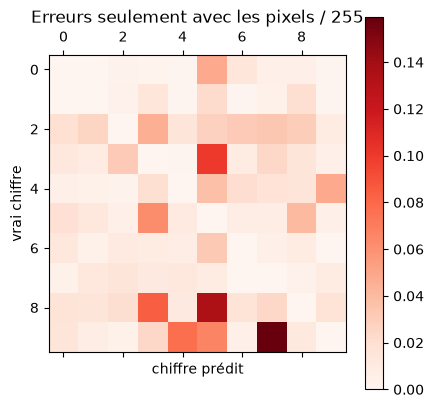

In [53]:
meilleur = modeles["pixels / 255"]                 # on peut mettre ici un autre nom d'essai
matrice2 = confusion_matrix(y_test, meilleur.predict(X_test_n))
sans_diag2 = matrice2 / matrice2.sum(axis=1, keepdims=True)
np.fill_diagonal(sans_diag2, 0)

plt.matshow(sans_diag2, cmap="Reds")
plt.title("Erreurs seulement avec les pixels / 255")
plt.xlabel("chiffre prédit"); plt.ylabel("vrai chiffre")
plt.colorbar()
plt.show()

**Commentaire :** Cette matrice est celle du modèle « pixels / 255 » (test 0.822, le moins bon du tableau). Elle est **différente** de la première : les erreurs ne sont pas aux mêmes endroits. On voit surtout une **colonne « 5 » très foncée** : ce modèle prédit trop souvent un 5 pour des 3, des 8 ou des 0 (proportions allant jusqu'à environ 0,1 à 0,13), et la confusion la plus forte est maintenant des 9 prédits 7 (environ 0,15). Cela confirme que **les erreurs dépendent des hyperparamètres et de la préparation des données**, pas seulement du jeu de données : deux modèles avec la même accuracy peuvent se tromper à des endroits différents, il faut donc regarder la matrice et pas seulement un chiffre global.

### 2.5 (Subsidiary) Use learning curves to determine how much data is needed 

Plot the error curves using the training set size against the error under the form of zero-one loss (the ratio of errors): one curve for the results with the training set, and the other curve with the test set.<br> 
Remark: the learning will take more and more time, so be careful of the required computation time.

On veut voir combien de données il faut. On entraîne le modèle avec de plus en plus d'images (de 1/64 jusqu'à tout le jeu d'entraînement) et on trace l'erreur « zéro-un » (proportion d'images mal classées) sur l'entraînement et sur le test. Quand les deux courbes se rejoignent et ne baissent plus, ajouter des données ne sert plus à grand-chose. L'exécution peut durer quelques minutes.

n=   875 | erreur train=0.006 | erreur test=0.178
n=  1750 | erreur train=0.002 | erreur test=0.163
n=  3500 | erreur train=0.023 | erreur test=0.150
n=  7000 | erreur train=0.047 | erreur test=0.121
n= 14000 | erreur train=0.069 | erreur test=0.105
n= 28000 | erreur train=0.077 | erreur test=0.097
n= 56000 | erreur train=0.078 | erreur test=0.090
durée : 49 s


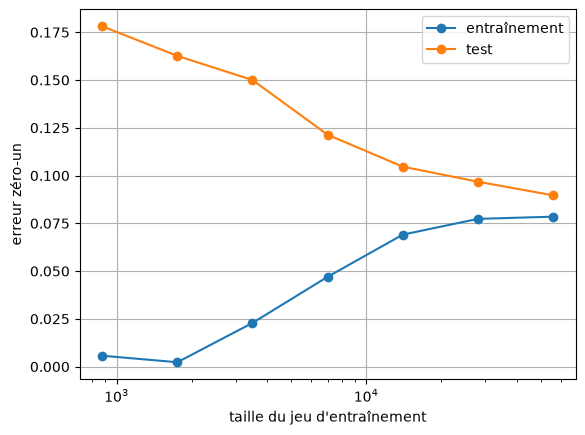

In [54]:
import time
fractions = [1/64, 1/32, 1/16, 1/8, 1/4, 1/2, 1]
tailles, erreur_train, erreur_test = [], [], []

debut = time.time()
for f in fractions:
    n = int(len(X_train) * f)
    Xa, ya = X_train[:n] / 255, y_train[:n]
    m = SGDClassifier(random_state=42).fit(Xa, ya)
    tailles.append(n)
    erreur_train.append(1 - m.score(Xa, ya))              # erreur zéro-un = 1 - accuracy
    erreur_test.append(1 - m.score(X_test_n, y_test))
    print(f"n={n:6d} | erreur train={erreur_train[-1]:.3f} | erreur test={erreur_test[-1]:.3f}")
print("durée :", round(time.time() - debut), "s")

plt.plot(tailles, erreur_train, "o-", label="entraînement")
plt.plot(tailles, erreur_test, "o-", label="test")
plt.xscale("log")
plt.xlabel("taille du jeu d'entraînement"); plt.ylabel("erreur zéro-un")
plt.legend(); plt.grid()
plt.show()

**Commentaire :**

| taille d'entraînement | erreur train | erreur test |
|---|---|---|
| 875 | 0.006 | 0.178 |
| 1 750 | 0.002 | 0.163 |
| 3 500 | 0.023 | 0.150 |
| 7 000 | 0.047 | 0.121 |
| 14 000 | 0.069 | 0.105 |
| 28 000 | 0.077 | 0.097 |
| 56 000 | 0.078 | 0.090 |

- Avec peu de données, l'erreur d'entraînement est presque nulle (le modèle apprend par cœur) mais l'erreur de test est grande (18 %) : **grand écart = surapprentissage**.
- Quand on ajoute des données, l'erreur d'entraînement **monte** (le modèle ne peut plus tout apprendre par cœur) et l'erreur de test **baisse**. Les deux courbes se rapprochent.
- À partir de 14 000 images environ, les courbes se rejoignent presque et **l'amélioration ralentit** : de 14 000 à 28 000 le test gagne 0.008, de 28 000 à 56 000 seulement 0.007, alors qu'on double la taille et donc le temps de calcul. À 56 000 l'écart entre les deux courbes n'est plus que de 0.012.
- **Pour décider à quelle taille s'arrêter :** vers 14 000 à 28 000 images on est déjà proche du résultat final (10,5 % et 9,7 % d'erreur contre 9,0 % avec tout). Le test ne baisserait plus beaucoup avec encore plus de données.
- L'erreur plafonne à environ **8 à 9 %**, et l'erreur d'entraînement n'atteint jamais 0 : le modèle est **trop simple** (linéaire sur des pixels) pour apprendre parfaitement, et il reste des chiffres vraiment mal écrits (erreurs intrinsèques vues en 2.3). Pour descendre plus bas il faudrait un **modèle plus riche** (réseau de neurones, noyaux...), pas plus de données.
- Remarque : cette courbe utilise les pixels divisés par 255. C'est pour cela que son premier point (0.178 d'erreur de test) correspond à l'accuracy de 0.822 vue en 2.4, et non aux 0.845 du modèle sur pixels bruts.

**Conclusion de la question 2.** Avec très peu de données, un classifieur linéaire se trompe surtout entre chiffres qui se ressemblent (4/9, 3/5/8) et surapprend. Les hyperparamètres (surtout `alpha`) réduisent un peu le surapprentissage, mais le gain est faible (+1 point). Plus de données aident nettement jusqu'à environ 14 000 à 28 000 images, ensuite on atteint un plateau d'environ 9 % d'erreur lié à la simplicité du modèle et aux chiffres mal écrits.